<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/PCVK_Ganjil_2026/blob/main/PCVK_M2_W2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modul 2 -  Representasi dan Karakteristik Citra Digital

**Mata Kuliah:** Pengolahan Citra dan Visi Komputer  
**Nama:** [Alfreda Dhaifullah Mahezwara]  
**NIM:** [2441107020219]


In [12]:
# Persiapan Awal
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
from skimage import io
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Tentukan path gambar utama Anda di sini
# Ubah path ini menyesuaikan file di drive Anda
img_path = '/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Lena.jpg'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---


## A. PERTANYAAN PRAKTIKUM


### Pertanyaan 1: Perbedaan `cv2_imshow()` dan `plt.imshow()` tanpa konversi warna


Menggunakan cv2_imshow (Kiri) dan plt.imshow (Kanan):


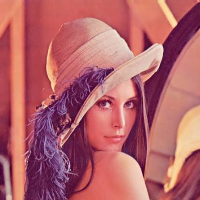

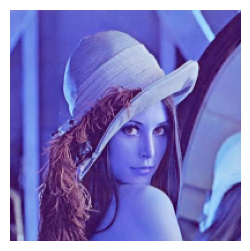

Nilai piksel (0,0) yang sama dari hasil cv.imread: [128 139 231]


In [14]:
img = cv.imread(img_path)
if img is not None:
    print("Menggunakan cv2_imshow (Kiri) dan plt.imshow (Kanan):")
    # cv2_imshow
    cv2_imshow(cv.resize(img, (200, 200)))

    # plt.imshow
    plt.figure(figsize=(3,3))
    plt.imshow(cv.resize(img, (200, 200)))
    plt.axis('off')
    plt.show()

    # Cetak nilai piksel
    print("Nilai piksel (0,0) yang sama dari hasil cv.imread:", img[0,0])
else:
    print("Gambar tidak ditemukan. Pastikan path benar.")


**Jawaban Analisis 1:**
Hasilnya berbeda karena `cv2_imshow` mengharapkan input citra dalam format BGR (bawaan pembacaan `cv.imread()`), sedangkan `plt.imshow` mengharapkan input berformat RGB. Tanpa dilakukan konversi, Matplotlib akan menganggap kanal Biru (B) pada indeks ke-0 sebagai Merah (R), sehingga warna gambar terlihat tertukar (merah menjadi biru, dan sebaliknya).


### Pertanyaan 2: Kanvas int16 vs int32


Canvas int16 - dtype: int16 | min: 0 | max: 0 | bytes: 540000
Canvas int32 - dtype: int32 | min: 0 | max: 0 | bytes: 1080000


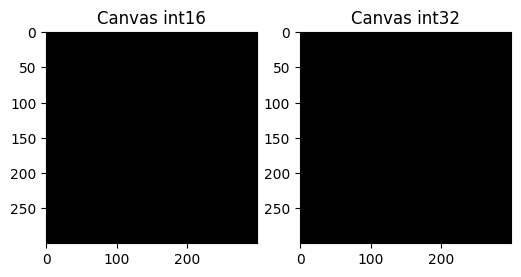

In [15]:
canvas_16 = np.zeros((300, 300, 3), dtype=np.int16)
canvas_32 = np.zeros((300, 300, 3), dtype=np.int32)

print("Canvas int16 - dtype:", canvas_16.dtype, "| min:", canvas_16.min(), "| max:", canvas_16.max(), "| bytes:", canvas_16.nbytes)
print("Canvas int32 - dtype:", canvas_32.dtype, "| min:", canvas_32.min(), "| max:", canvas_32.max(), "| bytes:", canvas_32.nbytes)

fig, axs = plt.subplots(1, 2, figsize=(6,3))
axs[0].imshow(canvas_16)
axs[0].set_title('Canvas int16')
axs[1].imshow(canvas_32)
axs[1].set_title('Canvas int32')
plt.show()


**Jawaban Analisis 2:**
- **Tampilan:** Keduanya tampil sama (hitam pekat) karena seluruh nilainya berisi angka 0.
- **Ukuran Memori:** Ukuran memorinya berbeda drastis. Canvas int32 menggunakan memori sebesar 1.080.000 bytes, dua kali lipat dari int16 (540.000 bytes) pada ukuran matriks yang sama. Hal ini terjadi karena tipe data int32 mengalokasikan 32-bit (4 byte) per elemen, sedangkan int16 hanya 16-bit (2 byte).


### Pertanyaan 3: Alasan Penggunaan `cv2_imshow` di Google Colab


**Jawaban Analisis 3:**
Fungsi bawaan `cv2.imshow()` memerlukan akses untuk memanggil dan membuat _window_ (jendela GUI) dari sistem operasi langsung, yang mana tidak dimungkinkan di lingkungan _cloud_ / web peramban seperti Jupyter Notebook atau Google Colab. Oleh karena itu, Colab menyediakan *patch* `cv2_imshow` untuk me-*render* gambar langsung menjadi elemen output sel.


### Pertanyaan 4: `skimage.io.imread()` vs `cv2.cvtColor`


Nilai piksel (0,0) hasil skimage.io.imread : [231 139 128]
Nilai piksel (0,0) hasil cv.cvtColor       : [231 139 128]


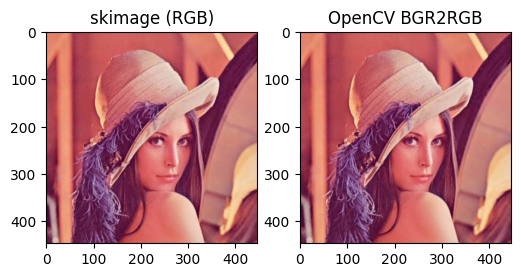

In [16]:
if img is not None:
    img_ski = io.imread(img_path)
    img_cv_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    print("Nilai piksel (0,0) hasil skimage.io.imread :", img_ski[0,0])
    print("Nilai piksel (0,0) hasil cv.cvtColor       :", img_cv_rgb[0,0])

    fig, axs = plt.subplots(1, 2, figsize=(6,3))
    axs[0].imshow(img_ski)
    axs[0].set_title('skimage (RGB)')
    axs[1].imshow(img_cv_rgb)
    axs[1].set_title('OpenCV BGR2RGB')
    plt.show()


**Jawaban Analisis 4:**
Keduanya menampilkan warna yang **sebenarnya (sama-sama berurutan RGB)**, sehingga secara visual dan nilai piksel tidak ada perbedaan. `skimage.io.imread()` membaca file langsung ke format RGB, sedangkan `cv.imread()` membaca ke format BGR yang kemudian dikonversi menjadi RGB melalui `cv.cvtColor`. Keduanya memiliki nilai array yang sama di setiap elemennya.


### Pertanyaan 5: Ukuran Tampilan vs Resolusi Citra


**Jawaban Analisis 5:**
Nilai `img.shape` **tidak akan ikut berubah** meskipun kita menggunakan parameter `figsize` yang sangat besar.

*Perbedaannya:* `figsize` merupakan parameter Matplotlib yang semata-mata memodifikasi ukuran kanvas penampil pada antarmuka, tanpa mengubah susunan matriks data asli. Sebaliknya, mengubah ukuran citra (seperti `cv.resize`) secara harfiah akan menyusun ulang matriks piksel, mengubah resolusinya (serta nilai `shape`-nya) melalui proses interpolasi.


---


## B. TUGAS PRAKTIKUM - PENERAPAN


### 1. Kombinasi Kanal Merah-Biru dan Hijau-Biru


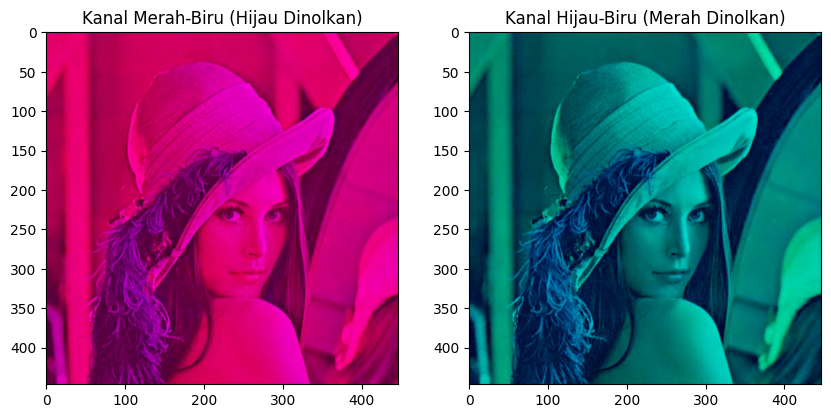

In [17]:
if img is not None:
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Merah-Biru (Nol-kan kanal Hijau/indeks 1)
    img_rb = img_rgb.copy()
    img_rb[:, :, 1] = 0

    # Hijau-Biru (Nol-kan kanal Merah/indeks 0)
    img_gb = img_rgb.copy()
    img_gb[:, :, 0] = 0

    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    axs[0].imshow(img_rb)
    axs[0].set_title('Kanal Merah-Biru (Hijau Dinolkan)')
    axs[1].imshow(img_gb)
    axs[1].set_title('Kanal Hijau-Biru (Merah Dinolkan)')
    plt.show()


### 2. Pencerminan Citra (Flip)


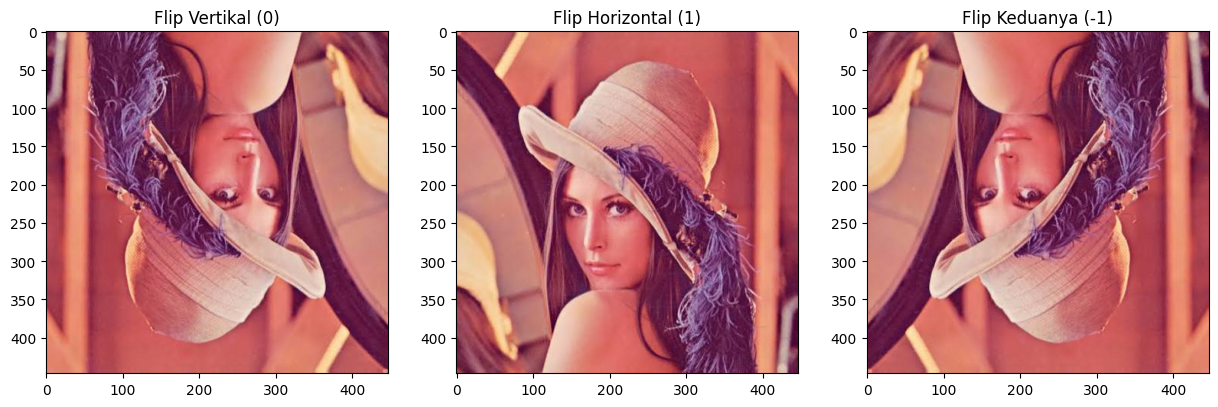

In [18]:
if img is not None:
    # 0 = vertikal, 1 = horizontal, -1 = keduanya
    flip_v = cv.flip(img_rgb, 0)
    flip_h = cv.flip(img_rgb, 1)
    flip_vh = cv.flip(img_rgb, -1)

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(flip_v)
    axs[0].set_title('Flip Vertikal (0)')
    axs[1].imshow(flip_h)
    axs[1].set_title('Flip Horizontal (1)')
    axs[2].imshow(flip_vh)
    axs[2].set_title('Flip Keduanya (-1)')
    plt.show()


### 3. Menggambar Geometri dan Teks


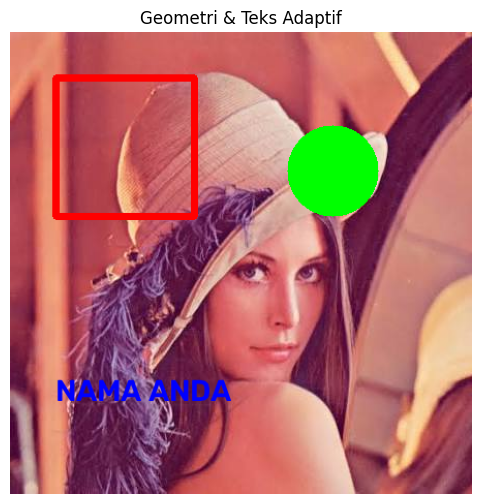

In [19]:
if img is not None:
    img_draw = img_rgb.copy()
    h, w = img_draw.shape[:2]

    # Ukuran adaptif
    cv.rectangle(img_draw, (int(w*0.1), int(h*0.1)), (int(w*0.4), int(h*0.4)), (255, 0, 0), 5)
    cv.circle(img_draw, (int(w*0.7), int(h*0.3)), int(w*0.1), (0, 255, 0), -1)
    cv.putText(img_draw, "NAMA ANDA", (int(w*0.1), int(h*0.8)), cv.FONT_HERSHEY_SIMPLEX, max(1, w/500), (0, 0, 255), 3, cv.LINE_AA)

    plt.figure(figsize=(6,6))
    plt.imshow(img_draw)
    plt.title("Geometri & Teks Adaptif")
    plt.axis('off')
    plt.show()


---


## C. TUGAS PRAKTIKUM - ANALISA


**Pertanyaan:** Berapa persentase piksel dalam citra yang merupakan piksel sangat terang (nilai keabuan di atas 200)?


In [20]:
if img is not None:
    # Konversi ke Grayscale untuk analisis intensitas
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Hitung jumlah piksel dengan nilai > 200
    bright_pixels = np.sum(img_gray > 200)
    total_pixels = img_gray.size

    percentage = (bright_pixels / total_pixels) * 100

    print(f"Total Piksel: {total_pixels}")
    print(f"Piksel Terang (>200): {bright_pixels}")
    print(f"Persentase Piksel Terang: {percentage:.2f}%")


Total Piksel: 199809
Piksel Terang (>200): 12409
Persentase Piksel Terang: 6.21%


**Kesimpulan:**
Melalui kode di atas, kita dapat menganalisis distribusi cahaya (eksposur) secara sederhana. Apabila persentase tinggi, maka foto cenderung mengalami *overexposure* atau didominasi oleh objek berwarna cerah/putih.


---


## D. TUGAS PRAKTIKUM - APLIKASI


### Studi Kasus 1: Label Identitas Dokumentasi (Bar Adaptif)


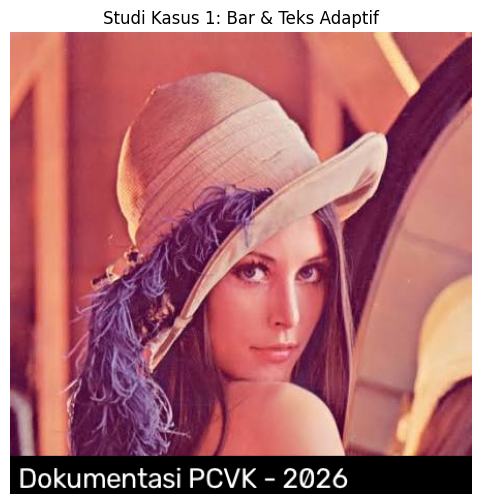

In [21]:
def add_adaptive_label(image, text="Dokumentasi PCVK - 2026"):
    img_out = image.copy()
    h, w = img_out.shape[:2]

    # Bar tinggi 1/12 dari gambar
    bar_height = max(1, h // 12)

    # Gambar bar hitam di bawah
    cv.rectangle(img_out, (0, h - bar_height), (w, h), (0, 0, 0), -1)

    # Kalkulasi ukuran font
    font_scale = bar_height / 40.0
    thickness = max(1, int(font_scale * 2))

    # Tempatkan teks
    text_size = cv.getTextSize(text, cv.FONT_HERSHEY_SIMPLEX, font_scale, thickness)[0]
    text_x = int(w * 0.02)
    text_y = h - ((bar_height - text_size[1]) // 2)

    cv.putText(img_out, text, (text_x, text_y), cv.FONT_HERSHEY_SIMPLEX, font_scale, (255, 255, 255), thickness, cv.LINE_AA)

    return img_out

if img is not None:
    res_kasus1 = add_adaptive_label(img_rgb)

    plt.figure(figsize=(8,6))
    plt.imshow(res_kasus1)
    plt.title("Studi Kasus 1: Bar & Teks Adaptif")
    plt.axis('off')
    plt.show()


### Studi Kasus 2: Bingkai Thumbnail Persegi 1:1


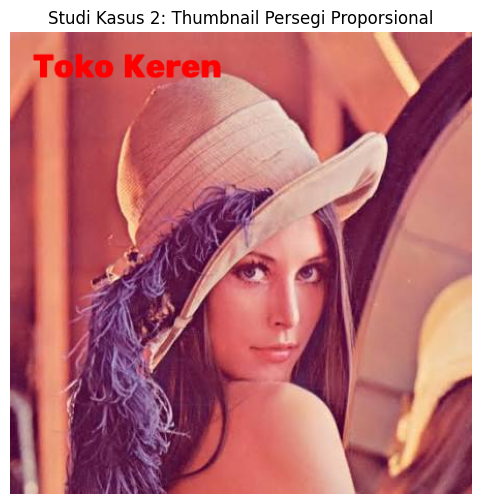

In [22]:
def make_square_thumbnail(image, bg_color=(240, 240, 240)):
    h, w = image.shape[:2]
    size = max(h, w)

    # Buat kanvas persegi
    canvas = np.full((size, size, 3), bg_color, dtype=np.uint8)

    # Hitung titik tengah
    y_off = (size - h) // 2
    x_off = (size - w) // 2

    # Salin citra ke tengah kanvas
    canvas[y_off:y_off+h, x_off:x_off+w] = image

    # Tambahkan teks / Logo adaptif
    text = "Toko Keren"
    font_scale = size / 400.0
    thickness = max(1, int(font_scale * 2))
    cv.putText(canvas, text, (int(size*0.05), int(size*0.1)), cv.FONT_HERSHEY_DUPLEX, font_scale, (255, 0, 0), thickness, cv.LINE_AA)

    return canvas

if img is not None:
    res_kasus2 = make_square_thumbnail(img_rgb)

    plt.figure(figsize=(6,6))
    plt.imshow(res_kasus2)
    plt.title("Studi Kasus 2: Thumbnail Persegi Proporsional")
    plt.axis('off')
    plt.show()
